# Task 1 – Truck Detection (YOLOv8-OBB)
Runtime → Change runtime type → **GPU**

In [1]:
!pip install -q ultralytics roboflow gradio

## 1. Dataset
Add your Roboflow key in Colab Secrets (🔑 icon) as `ROBOFLOW_API_KEY`.

In [2]:
from google.colab import userdata
from roboflow import Roboflow

rf = Roboflow(api_key="KkbIEI7hsSEqAoBmMFbn")
dataset = rf.workspace("ruiee11s-workspace").project("my-first-project-7jvrg").version(1).download("yolov8-obb", overwrite=True)
DATA = f"{dataset.location}/data.yaml"

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to My-First-Project-1 in yolov8-obb:: 100%|██████████| 217/217 [00:00<00:00, 9211.81it/s]


In [3]:
import glob, os
import numpy as np

# fix boxes that go outside the image
for f in glob.glob(f"{dataset.location}/*/labels/*.txt"):
    lines = []
    for l in open(f):
        v = l.split()
        if v:
            pts = np.clip(np.array(v[1:], float), 0, 1)
            lines.append(v[0] + " " + " ".join(f"{p:.6f}" for p in pts))
    open(f, "w").write("\n".join(lines) + "\n")

for f in glob.glob(f"{dataset.location}/*/labels.cache"):
    os.remove(f)

In [4]:
import glob, os, yaml
import pandas as pd
from collections import Counter
from ultralytics import YOLO

names = yaml.safe_load(open(DATA))["names"]

def class_counts(split):
    c = Counter()
    for f in glob.glob(f"{dataset.location}/{split}/labels/*.txt"):
        c.update(names[int(l.split()[0])] for l in open(f) if l.strip())
    return c

pd.DataFrame({s: {"images": len(glob.glob(f"{dataset.location}/{s}/images/*")), **class_counts(s)}
              for s in ["train", "valid", "test"]}).fillna(0).astype(int)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


,train,valid,test
images,93,8,5
small,30,3,2
med,30,3,2
large,39,1,1
object,0,1,0


## 2. Hyperparameter experiments

In [5]:
runs = {
    "baseline":  dict(model="yolov8n-obb.pt", epochs=50,  imgsz=640),
    "low_scale": dict(model="yolov8n-obb.pt", epochs=50,  imgsz=640, scale=0.1),
    "more_ep":   dict(model="yolov8n-obb.pt", epochs=100, imgsz=640, scale=0.1),
    "small":     dict(model="yolov8s-obb.pt", epochs=50,  imgsz=640, scale=0.1),
}

rows = []
for name, cfg in runs.items():
    cfg = cfg.copy()
    model = YOLO(cfg.pop("model"))
    model.train(data=DATA, name=name, exist_ok=True, seed=0, verbose=False, **cfg)
    best = YOLO(f"runs/obb/{name}/weights/best.pt")
    v = best.val(data=DATA, split="val", verbose=False)
    t = best.val(data=DATA, split="test", verbose=False)
    rows.append({"run": name, "val_mAP50": v.box.map50, "val_mAP50-95": v.box.map,
                 "test_mAP50": t.box.map50, "test_P": t.box.mp, "test_R": t.box.mr,
                 "ms/img": t.speed["inference"]})

results = pd.DataFrame(rows).round(3).sort_values("val_mAP50", ascending=False)
results

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/My-First-Project-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-obb.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline, nbs=64, nms=None, opset=None, optimiz

,run,val_mAP50,val_mAP50-95,test_mAP50,test_P,test_R,ms/img
0,baseline,0.788,0.498,0.608,0.324,0.823,4.225
1,low_scale,0.684,0.498,0.884,0.348,0.980,1.885
2,more_ep,0.684,0.496,0.939,0.735,0.972,2.023
3,small,0.672,0.474,0.829,0.516,0.851,4.242


Pick the best run by **validation** mAP (not test).

In [6]:
BEST = results.iloc[0]["run"]
model = YOLO(f"runs/obb/{BEST}/weights/best.pt")
m = model.val(data=DATA, split="test")
print(BEST)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLOv8n-obb summary (fused): 81 layers, 3,077,999 parameters, 0 gradients, 8.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1222.7±285.1 MB/s, size: 26.4 KB)
val: Scanning /content/My-First-Project-1/test/labels.cache... 5 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5/5 1.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 16.2it/s 0.1s
                   all          5          5      0.324      0.823      0.608      0.514
                 large          1          1      0.286          1      0.332      0.199
                   med          2          2      0.468      0.468      0.497      0.448
                 small          2          2      0.218          1      0.995      0.895
Speed: 0.3ms preprocess, 1.9ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/runs/obb/val-9
basel

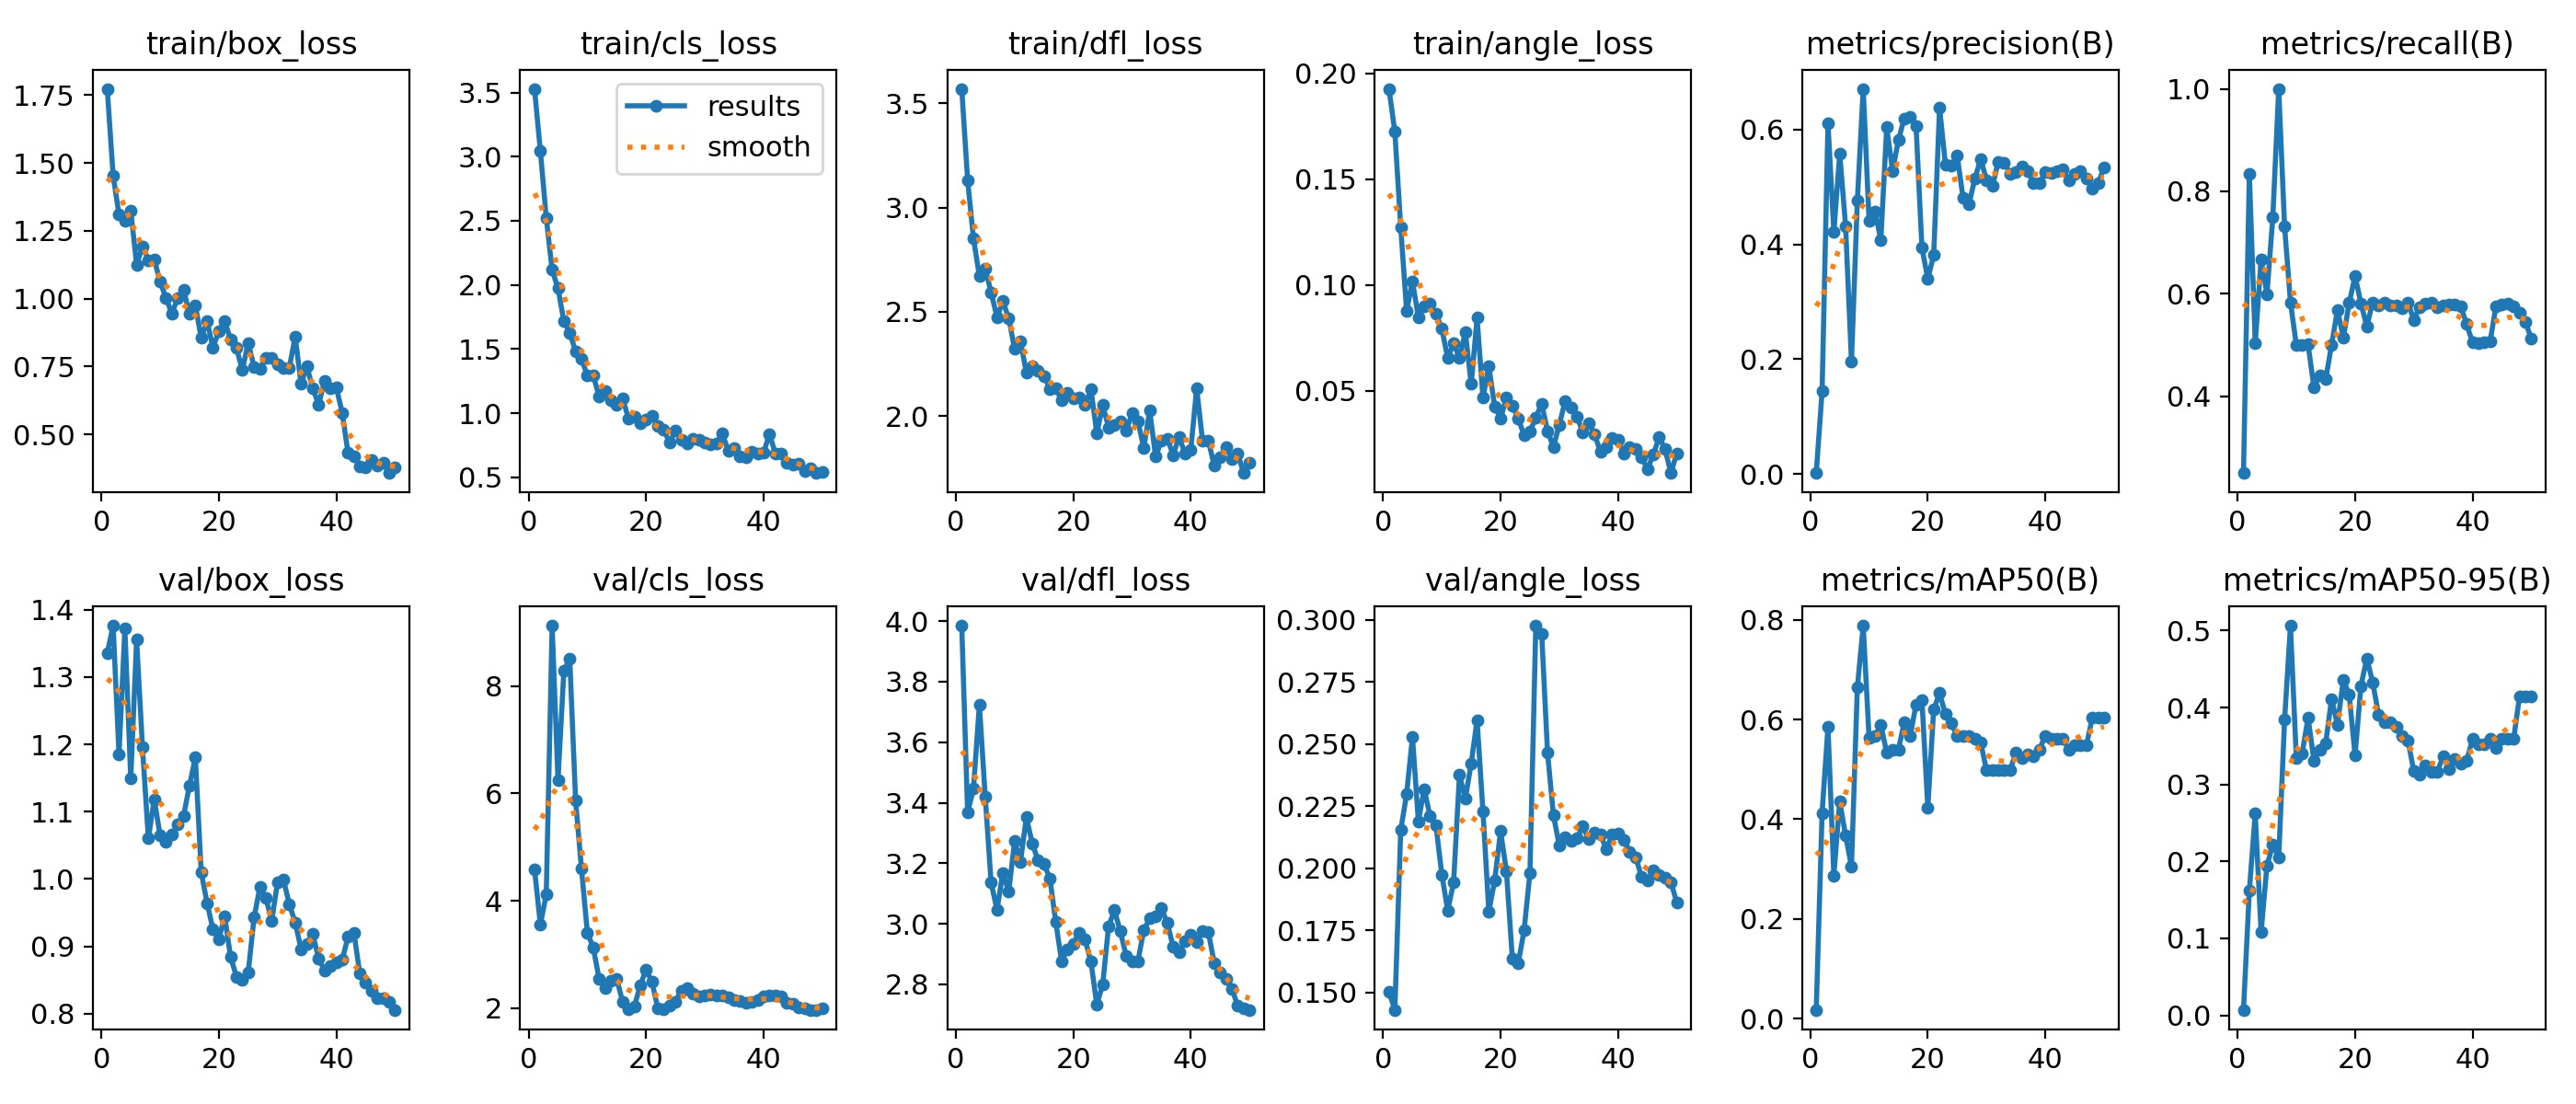

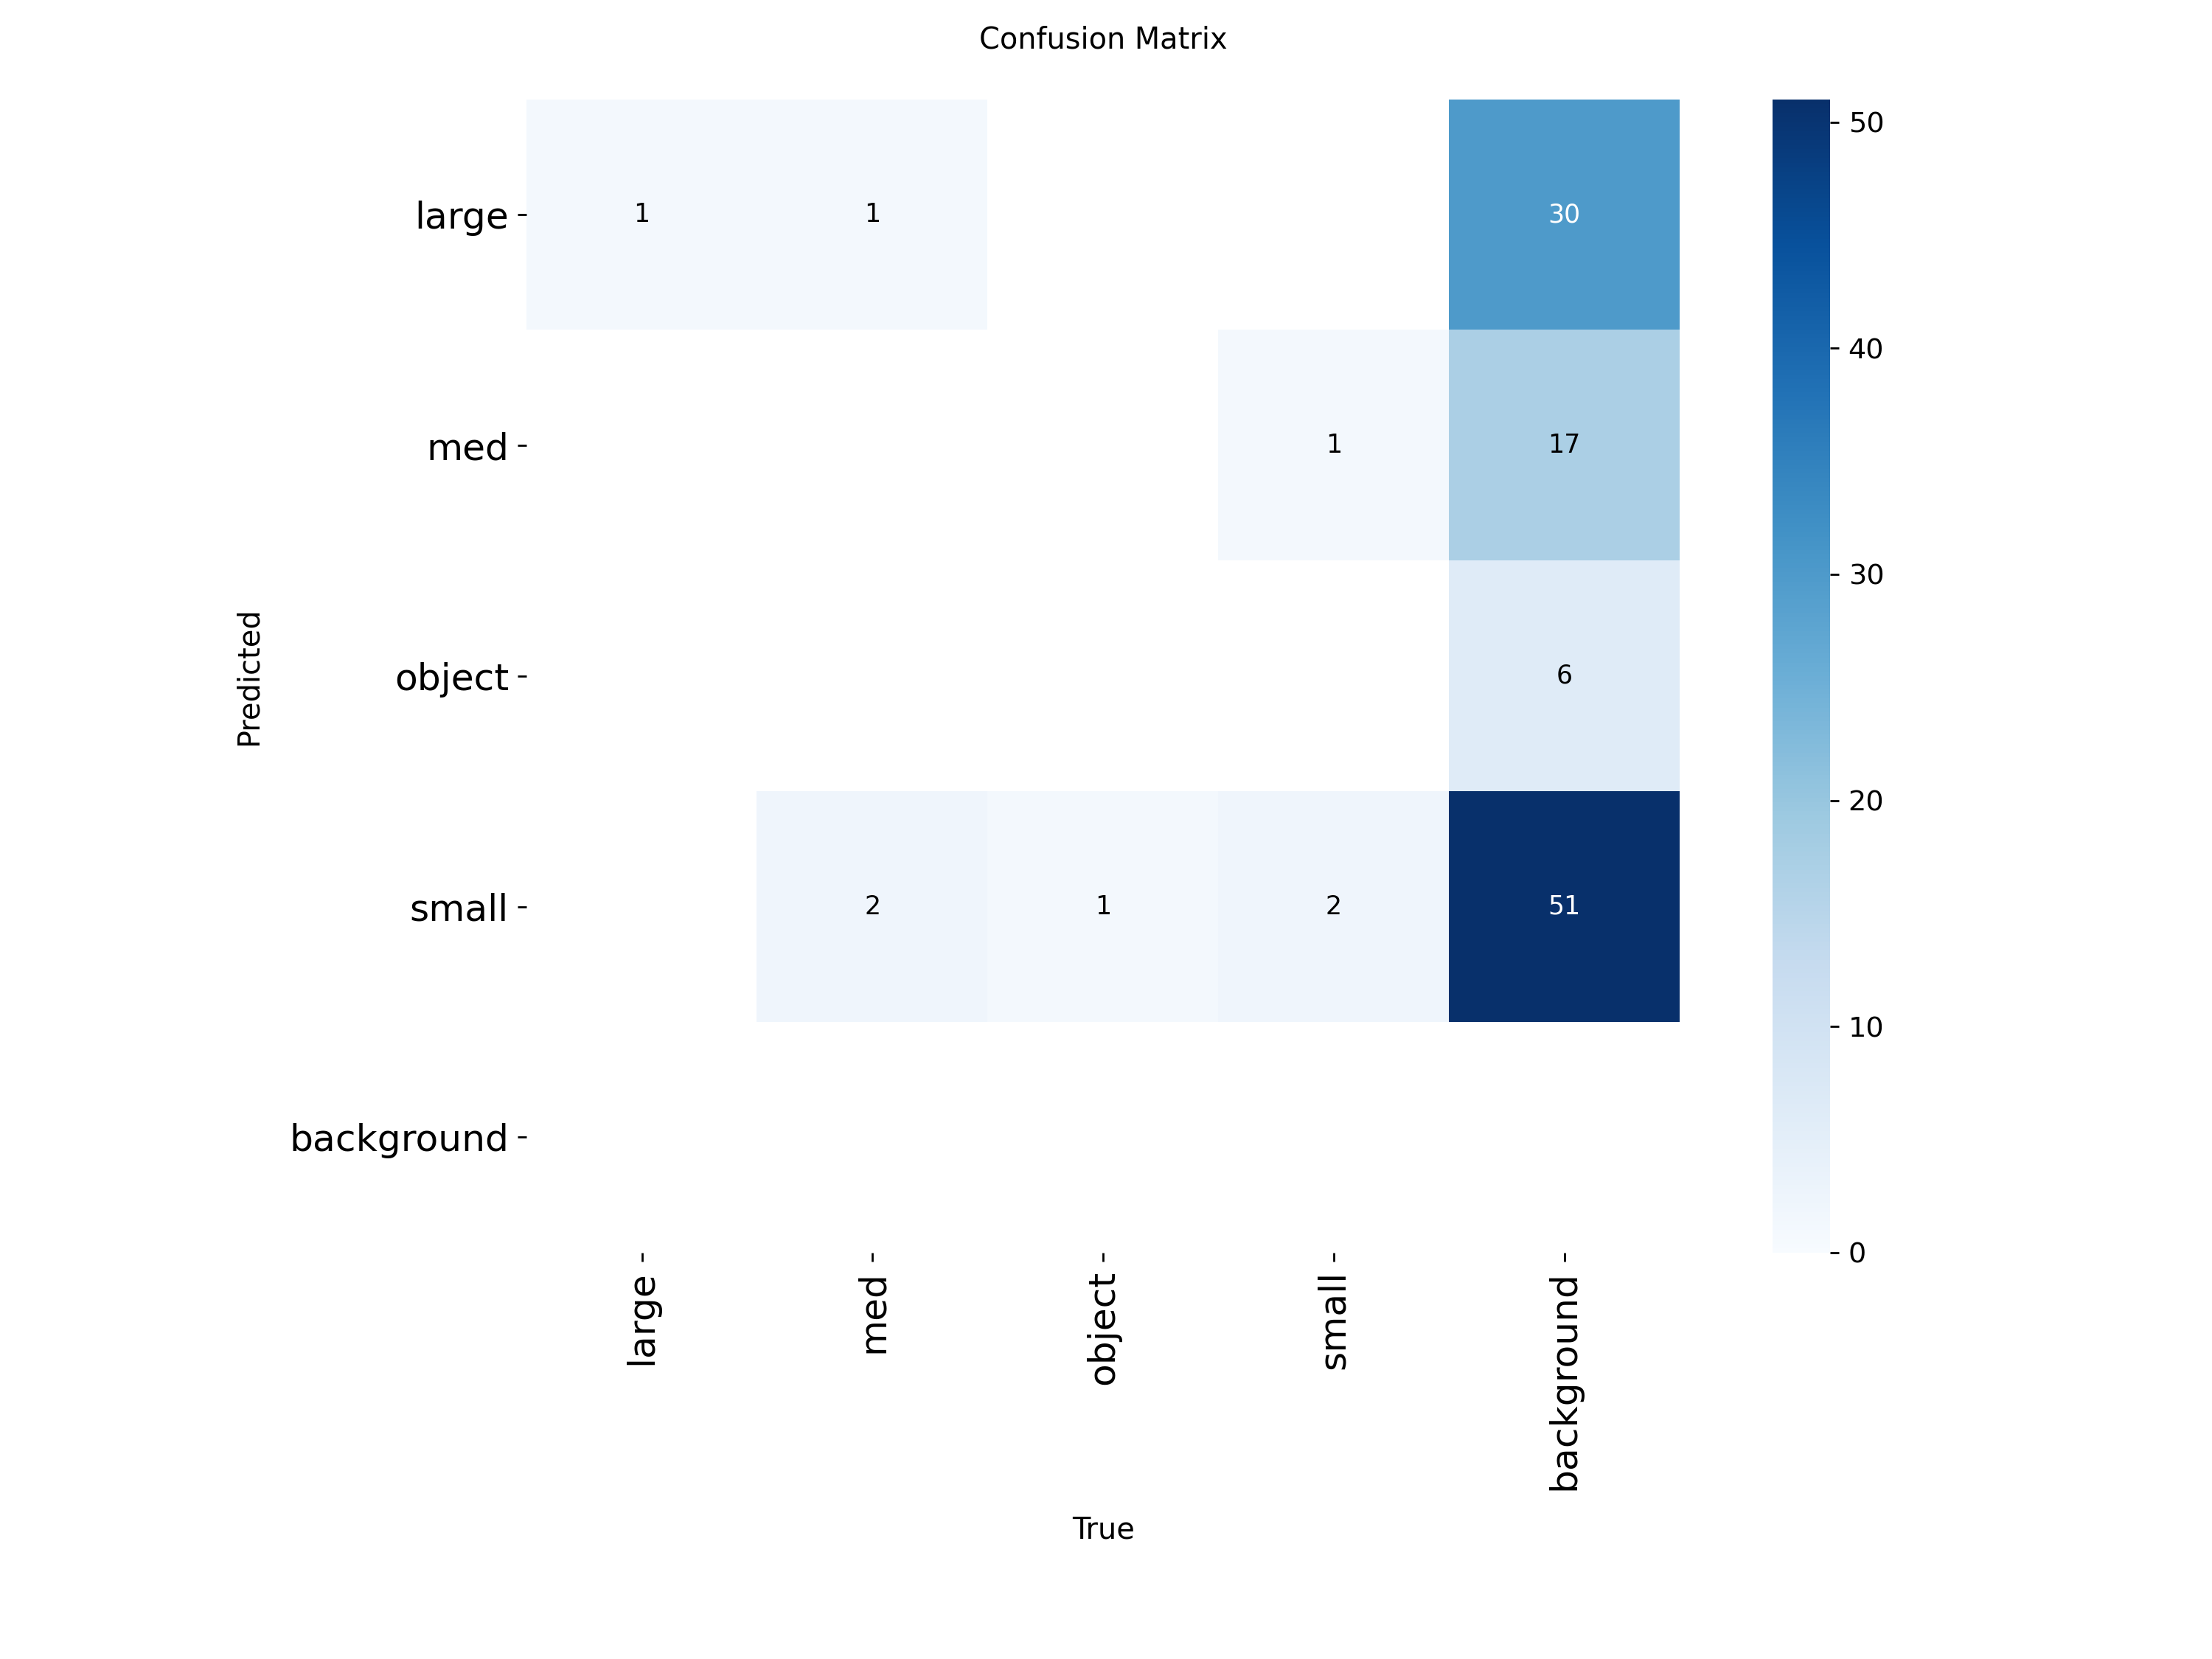

In [7]:
from IPython.display import Image, display
for f in ["results.png", "confusion_matrix.png"]:
    display(Image(filename=f"runs/obb/{BEST}/{f}", width=650))

## 3. What is detected and what is missed

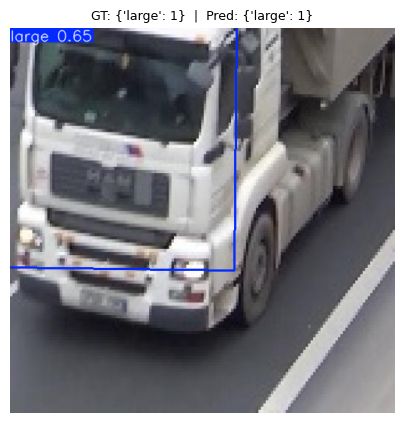

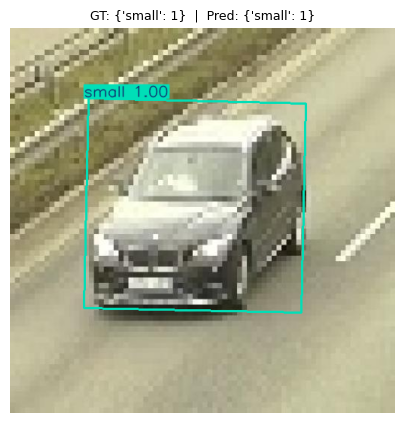

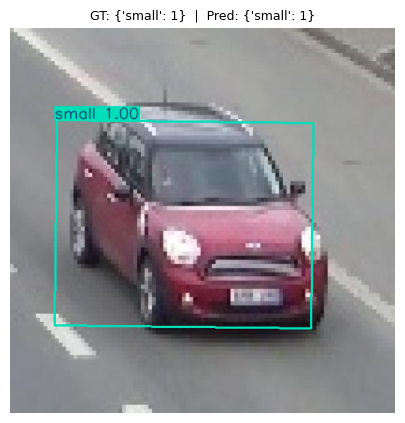

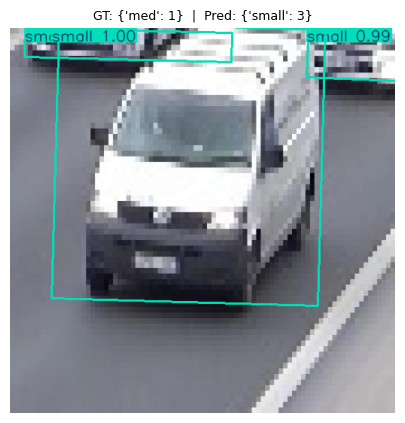

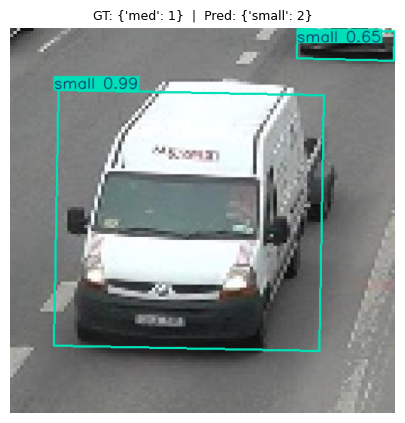

,image,ground_truth,predicted
0,Image_000012_jpg.rf.,{'large': 1},{'large': 1}
1,Image_001619_jpg.rf.,{'small': 1},{'small': 1}
2,Image_001621_jpg.rf.,{'small': 1},{'small': 1}
3,Image_014343_jpg.rf.,{'med': 1},{'small': 3}
4,Image_014360_jpg.rf.,{'med': 1},{'small': 2}


In [8]:
import matplotlib.pyplot as plt

PRED = dict(conf=0.5, iou=0.3, agnostic_nms=True, verbose=False)

test_imgs = sorted(glob.glob(f"{dataset.location}/test/images/*"))
rows = []
for r in model.predict(test_imgs, **PRED):
    lbl = r.path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    gt = Counter(names[int(l.split()[0])] for l in open(lbl) if l.strip())
    pred = Counter(r.names[int(c)] for c in r.obb.cls)
    rows.append({"image": os.path.basename(r.path)[:20], "ground_truth": dict(gt), "predicted": dict(pred)})

    plt.figure(figsize=(6, 5))
    plt.imshow(r.plot()[..., ::-1]); plt.axis("off")
    plt.title(f"GT: {dict(gt)}  |  Pred: {dict(pred)}", fontsize=9); plt.show()

pd.DataFrame(rows)

## 4. Demo (Gradio)

In [9]:
import gradio as gr
import cv2

def detect_image(img):
    return model.predict(img, **PRED)[0].plot()[..., ::-1]

def detect_video(path):
    out = "out.mp4"
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    w, h = int(cap.get(3)), int(cap.get(4))
    writer = cv2.VideoWriter(out, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    while True:
        ok, frame = cap.read()
        if not ok: break
        writer.write(model.predict(frame, **PRED)[0].plot())
    cap.release(); writer.release()
    return out

gr.TabbedInterface(
    [gr.Interface(detect_image, gr.Image(type="pil"), gr.Image()),
     gr.Interface(detect_video, gr.Video(), gr.Video())],
    ["Image", "Video"], title="Truck Detection"
).launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://29aa711b8be70f8661.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 5. Save model

In [10]:
from google.colab import files
files.download(f"runs/obb/{BEST}/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>